In [1]:
#importanto bibliotecas 
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.datasets import load_breast_cancer
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression  #modelo para comparação
from sklearn.ensemble import RandomForestClassifier  #modelo para comparação
from xgboost import XGBClassifier  #modelo para comparação
from sklearn import metrics

In [2]:
data = load_breast_cancer(as_frame=True)
df = data.frame  # tabela com as características e a coluna 
df.head()  # mostra as 5 primeiras linhas

,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


In [3]:
df.isnull().sum().sum()  # total de valores nulos
df["target"].value_counts()  # quantos casos há em cada classe

target
1    357
0    212
Name: count, dtype: int64

In [4]:
x = df.drop(columns=["target"])  # características
y = df["target"]  # alvo

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.3, stratify=y, random_state=42)
x_train.shape, x_test.shape

((398, 30), (171, 30))

In [5]:
scaler = StandardScaler()

x_train_scaled = pd.DataFrame(scaler.fit_transform(x_train), columns=x.columns, index=x_train.index)
x_test_scaled = pd.DataFrame(scaler.transform(x_test), columns=x.columns, index=x_test.index)

In [6]:
model1 = LogisticRegression(max_iter=1000) #calcula a probabilidade de cada classe
model1.fit(x_train_scaled, y_train)

model2 = RandomForestClassifier(n_estimators=200, min_samples_leaf=5, n_jobs=-1, random_state=42)
model2.fit(x_train, y_train) 

model3 = XGBClassifier(n_estimators=200, max_depth=3, learning_rate=0.1, n_jobs=-1, random_state=42, eval_metric="logloss")
model3.fit(x_train, y_train)

,"objective objective: str | xgboost.sklearn._SklObjWProto | typing.Callable[[typing.Any, typing.Any], typing.Tuple[numpy.ndarray, numpy.ndarray]] | NoneSpecify the learning task and the corresponding learning objective or a customobjective function to be used.For custom objective, see :doc:`/tutorials/custom_metric_obj` and:ref:`custom-obj-metric` for more information, along with the end note forfunction signatures.",'binary:logistic'
,"base_score base_score: float | typing.List[float] | NoneThe initial prediction score of all instances, global bias.",None
,booster,None
,"callbacks callbacks: typing.List[xgboost.callback.TrainingCallback] | NoneList of callback functions that are applied at end of each iteration.It is possible to use predefined callbacks by using:ref:`Callback API `... note:: States in callback are not preserved during training, which means callback objects can not be reused for multiple training sessions without reinitialization or deepcopy... code-block:: python for params in parameters_grid: # be sure to (re)initialize the callbacks before each run callbacks = [xgb.callback.LearningRateScheduler(custom_rates)] reg = xgboost.XGBRegressor(**params, callbacks=callbacks) reg.fit(X, y)",None
,colsample_bylevel colsample_bylevel: float | NoneSubsample ratio of columns for each level.,None
,colsample_bynode colsample_bynode: float | NoneSubsample ratio of columns for each split.,None
,colsample_bytree colsample_bytree: float | NoneSubsample ratio of columns when constructing each tree.,None
,"device device: str | None.. versionadded:: 2.0.0Device ordinal, available options are `cpu`, `cuda`, and `gpu`.",None
,"early_stopping_rounds early_stopping_rounds: int | None.. versionadded:: 1.6.0- Activates early stopping. Validation metric needs to improve at least once in every **early_stopping_rounds** round(s) to continue training. Requires at least one item in **eval_set** in :py:meth:`fit`.- If early stopping occurs, the model will have two additional attributes: :py:attr:`best_score` and :py:attr:`best_iteration`. These are used by the :py:meth:`predict` and :py:meth:`apply` methods to determine the optimal number of trees during inference. If users want to access the full model (including trees built after early stopping), they can specify the `iteration_range` in these inference methods. In addition, other utilities like model plotting can also use the entire model.- If you prefer to discard the trees after `best_iteration`, consider using the callback function :py:class:`xgboost.callback.EarlyStopping`.- If there's more than one item in **eval_set**, the last entry will be used for early stopping. If there's more than one metric in **eval_metric**, the last metric will be used for early stopping.",None
,enable_categorical enable_categorical: boolSee the same parameter of :py:class:`DMatrix` for details.,False
,"eval_metric eval_metric: str | typing.List[str | typing.Callable] | typing.Callable | None.. versionadded:: 1.6.0Metric used for monitoring the training result and early stopping. It can be astring or list of strings as names of predefined metric in XGBoost (See:doc:`/parameter`), one of the metrics in :py:mod:`sklearn.metrics`, or anyother user defined metric that looks like `sklearn.metrics`.If custom objective is also provided, then custom metric should implement thecorresponding reverse link function.Unlike the `scoring` parameter commonly used in scikit-learn, when a callableobject is provided, it's assumed to be a cost function and by default XGBoostwill minimize the result during early stopping.For advanced usage on Early stopping like directly choosing to maximize insteadof minimize, see :py:obj:`xgboost.callback.EarlyStopping`.See :doc:`/tutorials/custom_metric_obj` and :ref:`custom-obj-metric` for moreinformation... code-block:: python from sklearn.datasets import load_diabetes from sklearn.metrics import mean_absolute_error X, y = load_diabetes(return_X_y=True) reg = xgb.XGBRegressor( tree_meth

In [7]:
modelos = {
    "Regressão Logística": (model1, x_train_scaled, x_test_scaled),
    "Random Forest": (model2, x_train, x_test),
    "XGBoost": (model3, x_train, x_test),
}

for nome, (modelo, xtr, xte) in modelos.items():
    auc_treino = metrics.roc_auc_score(y_train, modelo.predict_proba(xtr)[:, 1])
    auc_teste = metrics.roc_auc_score(y_test, modelo.predict_proba(xte)[:, 1])
    print(f"{nome}: AUC treino = {auc_treino:.3f} | AUC teste = {auc_teste:.3f}")

Regressão Logística: AUC treino = 0.997 | AUC teste = 0.998
Random Forest: AUC treino = 0.998 | AUC teste = 0.991
XGBoost: AUC treino = 1.000 | AUC teste = 0.995


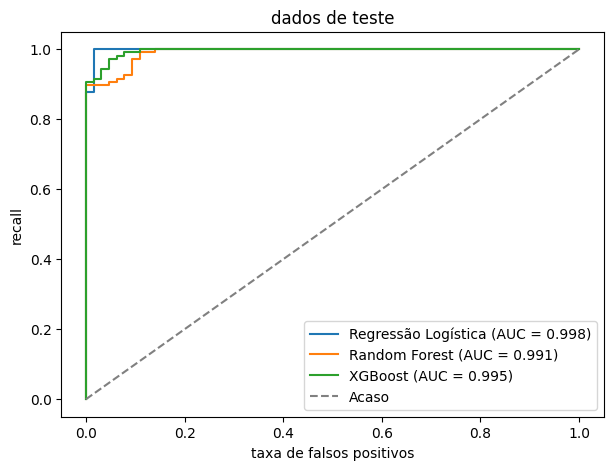

In [9]:
plt.figure(figsize=(7, 5))

for nome, (modelo, xtr, xte) in modelos.items():
    prob = modelo.predict_proba(xte)[:, 1]
    fpr, tpr, _ = metrics.roc_curve(y_test, prob)
    auc = metrics.roc_auc_score(y_test, prob)
    plt.plot(fpr, tpr, label=f"{nome} (AUC = {auc:.3f})")

plt.plot([0, 1], [0, 1], linestyle="--", color="gray", label="Acaso")
plt.xlabel("taxa de falsos positivos")
plt.ylabel("recall")
plt.title("dados de teste")
plt.legend()
plt.show()